# Ingeniería de características SMART — MC1

Se calculan medias móviles, cambios de media y conteos para **seis señales** (`R_1`, `N_1`, `R_5`, `N_5`, `R_9`, `N_9`) en ventanas de **7, 14 y 30 días**. Los cálculos se realizan en Snowflake, sobre la tabla Gold, sin modificar tablas ni descargar la telemetría completa.

## 1. Conexión a Snowflake

### Importe De librerias

In [11]:
import os
import re
import pandas as pd
from snowflake_io import create_spark_session, read_snowflake_query #Estas librerias en el directio de ejecucion de
# este notebook
from pyspark.sql import SparkSession

### Inicio de una sesion spark usando las credenciales de Snowflake registradas en el entorno de ejecucion
Este bloque permite generar una sesion Spark usando como backend la conexion a la nube de Snowflake para el computo
de metricas, y agregaciones a traves de SQL. Este sistema permite realizar un *offloading* de la mayoria de las
queries hacia snowflake para evitar el sobrecargo de la memoria local y el cluster de SPark de un solo nodo


In [16]:

#! 1. Inicio de sesion spark y validacion de variables de entorno y formato de las tablas importantes de la base de datos
spark: SparkSession = create_spark_session("mc1-smart-features")
database = os.environ["SNOWFLAKE_DATABASE"].strip()
if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_$]*", database):
    raise ValueError("Base de datos no válida")
gold = f'"{database}"."S_CDATOS_PSET2_GOLD"."FCT_SMART_DAILY_MC1"'
obt = f'"{database}"."S_CDATOS_PSET2_OBT"."OBT_MC1_RN"'



def consultar(sql, max_filas=30):
    # Solo recuperar tablas pequeñas; el trabajo se ejecuta en Snowflake.
    texto = sql.strip().rstrip(";")
    if not texto.upper().startswith(("SELECT", "WITH")) or ";" in texto:
        raise ValueError("Solo se permiten consultas SELECT")
    resultado = read_snowflake_query(
        spark, f"SELECT * FROM ({texto}) q LIMIT {max_filas + 1}",
        schema="S_CDATOS_PSET2_GOLD"
    ).toPandas()
    if len(resultado) > max_filas:
        raise ValueError("La consulta devuelve demasiadas filas")
    return resultado

print("Gold:", gold)
print("Obt:", obt)
print("Spark:",spark.version)
print("Spark:", spark.sparkContext)

Gold: "WXVGCFK_QF18928_S_CDATOS_PSET2_SNOWFLAKE_SHARE_1792893424527"."S_CDATOS_PSET2_GOLD"."FCT_SMART_DAILY_MC1"
Obt: "WXVGCFK_QF18928_S_CDATOS_PSET2_SNOWFLAKE_SHARE_1792893424527"."S_CDATOS_PSET2_OBT"."OBT_MC1_RN"
Spark: 4.0.4
Spark: <SparkContext master=local[*] appName=mc1-smart-features>


## 2. Cálculo de las características

La media y el conteo corresponden a la ventana actual, incluido el día observado. El cambio de media resta la ventana inmediatamente anterior. Se respetan **días calendario** y los valores nulos no se imputan.

### Configuracion base usando las claves de dos dispositivos de prueba de las tablas MC1 OBT que tengan Labels
Positivas

Usamos este apartado de configuracion para calcular las caracteristicas de los dispositivos SSD registrados en la
tabla final, siguiendo su trayectoria desde los registros de las tablas GOLD de donde se obtuvieron estas metricas
realmente. La siguiente funcion busca dos SSD con observaciones positivas y valida sus clave usando REGEX para
asegurar que sean validas. Luego las unifica en una lista para ser usadas como *structuered parameter* en las queries
 subsiguientes.

In [17]:
#! OJO: Esta celda requiere que se ejecute la conexion de la celda 1 previamente.

ssd_muestra = consultar(f"""
    SELECT DISTINCT SSD_KEY FROM {obt}
    WHERE LABEL_STATUS = 'POSITIVE'
    ORDER BY SSD_KEY LIMIT 2
""", max_filas=2)
if ssd_muestra.empty:
    raise RuntimeError("No se encontraron SSD con observaciones positivas")
claves = ssd_muestra["SSD_KEY"].astype(str).tolist()
if not all(re.fullmatch(r"[0-9a-fA-F]{64}", k) for k in claves):
    raise ValueError("Formato inesperado de SSD_KEY")
claves_sql = ", ".join(f"'{k}'" for k in claves)
ssd_muestra

,SSD_KEY
0,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...
1,0003a303b54fc970db661a2dc1985077db26375a9b0498...


### Calculo del mean, mean shift y count para las SMART R_1, N_1, R_5, N_5, R_9, N_9 en ventanas de 7, 14 y 30 días

#### SMART: R_1
Para la SMART R_1 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual −
promedio anterior*. Si falta una ventana, el resultado es NULL.

In [18]:
# Cálculos explícitos de R_1 para las tres ventanas.
consulta_r_1 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_1,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_1,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_1_MEAN_7D,
           COUNT(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_1_COUNT_7D,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS R_1_PREV_MEAN_7D,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_1_MEAN_14D,
           COUNT(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_1_COUNT_14D,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS R_1_PREV_MEAN_14D,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_1_MEAN_30D,
           COUNT(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_1_COUNT_30D,
           AVG(R_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS R_1_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_1,
           R_1_MEAN_7D,
           R_1_COUNT_7D,
           (R_1_MEAN_7D - R_1_PREV_MEAN_7D) AS R_1_MEAN_SHIFT_7D,
           R_1_MEAN_14D,
           R_1_COUNT_14D,
           (R_1_MEAN_14D - R_1_PREV_MEAN_14D) AS R_1_MEAN_SHIFT_14D,
           R_1_MEAN_30D,
           R_1_COUNT_30D,
           (R_1_MEAN_30D - R_1_PREV_MEAN_30D) AS R_1_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.R_1,
       f.R_1_MEAN_7D,
       f.R_1_COUNT_7D,
       f.R_1_MEAN_SHIFT_7D,
       f.R_1_MEAN_14D,
       f.R_1_COUNT_14D,
       f.R_1_MEAN_SHIFT_14D,
       f.R_1_MEAN_30D,
       f.R_1_COUNT_30D,
       f.R_1_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_r_1 = consultar(consulta_r_1, max_filas=100)
features_r_1

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,R_1,R_1_MEAN_7D,R_1_COUNT_7D,R_1_MEAN_SHIFT_7D,R_1_MEAN_14D,R_1_COUNT_14D,R_1_MEAN_SHIFT_14D,R_1_MEAN_30D,R_1_COUNT_30D,R_1_MEAN_SHIFT_30D
0,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-21,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,10,0E-9,0E-9,26,0E-9
1,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-20,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,10,0E-9,0E-9,26,0E-9
2,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-19,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,10,0E-9,0E-9,26,0E-9
3,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-18,POSITIVE,0.000000,0E-9,6,0E-9,0E-9,10,0E-9,0E-9,26,0E-9
4,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-17,POSITIVE,0.000000,0E-9,5,0E-9,0E-9,10,0E-9,0E-9,26,0E-9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-17,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
96,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-16,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
97,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-15,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,29,0E-9
98,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-14,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,28,0E-9


#### SMART: N_1
Para la SMART N_1 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual −
promedio anterior*. Si falta una ventana, el resultado es NULL. Esta es la version normalizada de la SMART R_1, y se
calcula de manera similar.

In [19]:
# Cálculos explícitos de N_1 para las tres ventanas.
consulta_n_1 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_1,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_1,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_1_MEAN_7D,
           COUNT(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_1_COUNT_7D,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS N_1_PREV_MEAN_7D,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_1_MEAN_14D,
           COUNT(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_1_COUNT_14D,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS N_1_PREV_MEAN_14D,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_1_MEAN_30D,
           COUNT(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_1_COUNT_30D,
           AVG(N_1) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS N_1_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_1,
           N_1_MEAN_7D,
           N_1_COUNT_7D,
           (N_1_MEAN_7D - N_1_PREV_MEAN_7D) AS N_1_MEAN_SHIFT_7D,
           N_1_MEAN_14D,
           N_1_COUNT_14D,
           (N_1_MEAN_14D - N_1_PREV_MEAN_14D) AS N_1_MEAN_SHIFT_14D,
           N_1_MEAN_30D,
           N_1_COUNT_30D,
           (N_1_MEAN_30D - N_1_PREV_MEAN_30D) AS N_1_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.N_1,
       f.N_1_MEAN_7D,
       f.N_1_COUNT_7D,
       f.N_1_MEAN_SHIFT_7D,
       f.N_1_MEAN_14D,
       f.N_1_COUNT_14D,
       f.N_1_MEAN_SHIFT_14D,
       f.N_1_MEAN_30D,
       f.N_1_COUNT_30D,
       f.N_1_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_n_1 = consultar(consulta_n_1, max_filas=100)
features_n_1

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,N_1,N_1_MEAN_7D,N_1_COUNT_7D,N_1_MEAN_SHIFT_7D,N_1_MEAN_14D,N_1_COUNT_14D,N_1_MEAN_SHIFT_14D,N_1_MEAN_30D,N_1_COUNT_30D,N_1_MEAN_SHIFT_30D
0,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-21,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,10,0E-9,100.000000000,26,0E-9
1,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-20,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,10,0E-9,100.000000000,26,0E-9
2,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-19,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,10,0E-9,100.000000000,26,0E-9
3,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-18,POSITIVE,100.000000,100.000000000,6,0E-9,100.000000000,10,0E-9,100.000000000,26,0E-9
4,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-17,POSITIVE,100.000000,100.000000000,5,0E-9,100.000000000,10,0E-9,100.000000000,26,0E-9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-05,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
96,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-04,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
97,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-03,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
98,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-02,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9


#### SMART: R_5
Para la SMART R_5 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual −
promedio anterior*. Si falta una ventana, el resultado es NULL.

In [20]:
# Cálculos explícitos de R_5 para las tres ventanas.
consulta_r_5 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_5,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_5,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_5_MEAN_7D,
           COUNT(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_5_COUNT_7D,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS R_5_PREV_MEAN_7D,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_5_MEAN_14D,
           COUNT(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_5_COUNT_14D,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS R_5_PREV_MEAN_14D,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_5_MEAN_30D,
           COUNT(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_5_COUNT_30D,
           AVG(R_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS R_5_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_5,
           R_5_MEAN_7D,
           R_5_COUNT_7D,
           (R_5_MEAN_7D - R_5_PREV_MEAN_7D) AS R_5_MEAN_SHIFT_7D,
           R_5_MEAN_14D,
           R_5_COUNT_14D,
           (R_5_MEAN_14D - R_5_PREV_MEAN_14D) AS R_5_MEAN_SHIFT_14D,
           R_5_MEAN_30D,
           R_5_COUNT_30D,
           (R_5_MEAN_30D - R_5_PREV_MEAN_30D) AS R_5_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.R_5,
       f.R_5_MEAN_7D,
       f.R_5_COUNT_7D,
       f.R_5_MEAN_SHIFT_7D,
       f.R_5_MEAN_14D,
       f.R_5_COUNT_14D,
       f.R_5_MEAN_SHIFT_14D,
       f.R_5_MEAN_30D,
       f.R_5_COUNT_30D,
       f.R_5_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_r_5 = consultar(consulta_r_5, max_filas=100)
features_r_5

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,R_5,R_5_MEAN_7D,R_5_COUNT_7D,R_5_MEAN_SHIFT_7D,R_5_MEAN_14D,R_5_COUNT_14D,R_5_MEAN_SHIFT_14D,R_5_MEAN_30D,R_5_COUNT_30D,R_5_MEAN_SHIFT_30D
0,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-25,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
1,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-24,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
2,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-23,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
3,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-22,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
4,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-21,POSITIVE,0.000000,0E-9,7,0E-9,0E-9,14,0E-9,0E-9,30,0E-9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-16,NEGATIVE,182.000000,182.000000000,7,0E-9,182.000000000,14,4.142857143,179.600000000,30,5.531034483
96,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-15,NEGATIVE,182.000000,182.000000000,7,0E-9,182.000000000,14,4.642857143,179.366666666,30,5.366666666
97,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-14,NEGATIVE,182.000000,182.000000000,7,0E-9,182.000000000,14,5.142857143,179.133333333,30,5.202298851
98,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-13,NEGATIVE,182.000000,182.000000000,7,0E-9,182.000000000,14,5.642857143,178.900000000,30,5.037931035


#### SMART: N_5
Para la SMART N_5 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual − promedio anterior*. Si falta una ventana, el resultado es NULL. Esta es la version normalizada de la SMART R_5, y se calcula de manera similar.

In [21]:
# Cálculos explícitos de N_5 para las tres ventanas.
consulta_n_5 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_5,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_5,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_5_MEAN_7D,
           COUNT(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_5_COUNT_7D,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS N_5_PREV_MEAN_7D,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_5_MEAN_14D,
           COUNT(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_5_COUNT_14D,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS N_5_PREV_MEAN_14D,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_5_MEAN_30D,
           COUNT(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_5_COUNT_30D,
           AVG(N_5) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS N_5_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_5,
           N_5_MEAN_7D,
           N_5_COUNT_7D,
           (N_5_MEAN_7D - N_5_PREV_MEAN_7D) AS N_5_MEAN_SHIFT_7D,
           N_5_MEAN_14D,
           N_5_COUNT_14D,
           (N_5_MEAN_14D - N_5_PREV_MEAN_14D) AS N_5_MEAN_SHIFT_14D,
           N_5_MEAN_30D,
           N_5_COUNT_30D,
           (N_5_MEAN_30D - N_5_PREV_MEAN_30D) AS N_5_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.N_5,
       f.N_5_MEAN_7D,
       f.N_5_COUNT_7D,
       f.N_5_MEAN_SHIFT_7D,
       f.N_5_MEAN_14D,
       f.N_5_COUNT_14D,
       f.N_5_MEAN_SHIFT_14D,
       f.N_5_MEAN_30D,
       f.N_5_COUNT_30D,
       f.N_5_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_n_5 = consultar(consulta_n_5, max_filas=100)
features_n_5

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,N_5,N_5_MEAN_7D,N_5_COUNT_7D,N_5_MEAN_SHIFT_7D,N_5_MEAN_14D,N_5_COUNT_14D,N_5_MEAN_SHIFT_14D,N_5_MEAN_30D,N_5_COUNT_30D,N_5_MEAN_SHIFT_30D
0,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-09-07,POSITIVE,100.000000,100.000000000,6,0E-9,100.000000000,13,0E-9,100.000000000,29,0E-9
1,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-09-05,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,30,0E-9
2,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-09-04,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,30,0E-9
3,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-09-03,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,30,0E-9
4,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-09-02,POSITIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,30,0E-9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-16,NEGATIVE,99.000000,99.000000000,7,0E-9,99.000000000,14,0E-9,99.000000000,30,0E-9
96,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-15,NEGATIVE,99.000000,99.000000000,7,0E-9,99.000000000,14,0E-9,99.000000000,30,0E-9
97,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-14,NEGATIVE,99.000000,99.000000000,7,0E-9,99.000000000,14,0E-9,99.000000000,30,0E-9
98,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-13,NEGATIVE,99.000000,99.000000000,7,0E-9,99.000000000,14,0E-9,99.000000000,30,0E-9


#### SMART: R_9
Para la SMART R_9 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual − promedio anterior*. Si falta una ventana, el resultado es NULL.

In [22]:
# Cálculos explícitos de R_9 para las tres ventanas.
consulta_r_9 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_9,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_9,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_9_MEAN_7D,
           COUNT(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS R_9_COUNT_7D,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS R_9_PREV_MEAN_7D,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_9_MEAN_14D,
           COUNT(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS R_9_COUNT_14D,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS R_9_PREV_MEAN_14D,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_9_MEAN_30D,
           COUNT(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS R_9_COUNT_30D,
           AVG(R_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS R_9_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, R_9,
           R_9_MEAN_7D,
           R_9_COUNT_7D,
           (R_9_MEAN_7D - R_9_PREV_MEAN_7D) AS R_9_MEAN_SHIFT_7D,
           R_9_MEAN_14D,
           R_9_COUNT_14D,
           (R_9_MEAN_14D - R_9_PREV_MEAN_14D) AS R_9_MEAN_SHIFT_14D,
           R_9_MEAN_30D,
           R_9_COUNT_30D,
           (R_9_MEAN_30D - R_9_PREV_MEAN_30D) AS R_9_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.R_9,
       f.R_9_MEAN_7D,
       f.R_9_COUNT_7D,
       f.R_9_MEAN_SHIFT_7D,
       f.R_9_MEAN_14D,
       f.R_9_COUNT_14D,
       f.R_9_MEAN_SHIFT_14D,
       f.R_9_MEAN_30D,
       f.R_9_COUNT_30D,
       f.R_9_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_r_9 = consultar(consulta_r_9, max_filas=100)
features_r_9

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,R_9,R_9_MEAN_7D,R_9_COUNT_7D,R_9_MEAN_SHIFT_7D,R_9_MEAN_14D,R_9_COUNT_14D,R_9_MEAN_SHIFT_14D,R_9_MEAN_30D,R_9_COUNT_30D,R_9_MEAN_SHIFT_30D
0,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-21,POSITIVE,7912.000000,7840.000000000,7,152.000000000,7794.400000000,10,374.400000000,7549.230769230,26,704.630769230
1,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-20,POSITIVE,7888.000000,7816.000000000,7,184.000000000,7760.800000000,10,364.800000000,7521.538461538,26,700.905128205
2,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-19,POSITIVE,7864.000000,7792.000000000,7,216.000000000,7727.200000000,10,355.200000000,7493.846153846,26,697.179487180
3,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-18,POSITIVE,7840.000000,7780.000000000,6,216.000000000,7693.600000000,10,345.600000000,7466.153846153,26,693.453846153
4,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-11-17,POSITIVE,7816.000000,7768.000000000,5,216.000000000,7660.000000000,10,336.000000000,7438.461538461,26,689.728205128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-16,NEGATIVE,7048.000000,6976.285714285,7,167.428571428,6892.571428571,14,335.571428571,6700.800000000,30,707.696551725
96,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-15,NEGATIVE,7024.000000,6952.428571428,7,167.571428571,6868.642857142,14,335.642857142,6676.833333333,30,708.557471265
97,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-14,NEGATIVE,7000.000000,6928.571428571,7,167.714285714,6844.714285714,14,335.714285714,6652.866666666,30,709.418390804
98,000035c97d82c585d0ae0a09dd82b7ed26d5f87f1c2e07...,51660,2018-10-13,NEGATIVE,6976.000000,6904.714285714,7,167.857142857,6820.785714285,14,335.785714285,6628.900000000,30,710.279310345


#### SMART: N_9
Para la SMART N_9 Se calculan MEAN, COUNT y MEAN_SHIFT en las tres ventanas, donde *MEAN_SHIFT = promedio actual − promedio anterior*. Si falta una ventana, el resultado es NULL. Esta es la version normalizada de la SMART R_9, y se calcula de manera similar.

In [23]:
# Cálculos explícitos de N_9 para las tres ventanas.
consulta_n_9 = f"""
WITH fuente AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_9,
           DATEDIFF('day', '1970-01-01'::DATE, OBSERVATION_DATE) AS DIA
    FROM {gold}
    WHERE SSD_KEY IN ({claves_sql})
), ventanas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_9,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_9_MEAN_7D,
           COUNT(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 6 PRECEDING AND CURRENT ROW) AS N_9_COUNT_7D,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND 7 PRECEDING) AS N_9_PREV_MEAN_7D,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_9_MEAN_14D,
           COUNT(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 13 PRECEDING AND CURRENT ROW) AS N_9_COUNT_14D,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 27 PRECEDING AND 14 PRECEDING) AS N_9_PREV_MEAN_14D,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_9_MEAN_30D,
           COUNT(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 29 PRECEDING AND CURRENT ROW) AS N_9_COUNT_30D,
           AVG(N_9) OVER (PARTITION BY SSD_KEY ORDER BY DIA RANGE BETWEEN 59 PRECEDING AND 30 PRECEDING) AS N_9_PREV_MEAN_30D
    FROM fuente
), calculadas AS (
    SELECT SSD_KEY, OBSERVATION_DATE, N_9,
           N_9_MEAN_7D,
           N_9_COUNT_7D,
           (N_9_MEAN_7D - N_9_PREV_MEAN_7D) AS N_9_MEAN_SHIFT_7D,
           N_9_MEAN_14D,
           N_9_COUNT_14D,
           (N_9_MEAN_14D - N_9_PREV_MEAN_14D) AS N_9_MEAN_SHIFT_14D,
           N_9_MEAN_30D,
           N_9_COUNT_30D,
           (N_9_MEAN_30D - N_9_PREV_MEAN_30D) AS N_9_MEAN_SHIFT_30D
    FROM ventanas
)
SELECT o.SSD_KEY, o.DISK_ID, o.OBSERVATION_DATE, o.LABEL_STATUS,
       f.N_9,
       f.N_9_MEAN_7D,
       f.N_9_COUNT_7D,
       f.N_9_MEAN_SHIFT_7D,
       f.N_9_MEAN_14D,
       f.N_9_COUNT_14D,
       f.N_9_MEAN_SHIFT_14D,
       f.N_9_MEAN_30D,
       f.N_9_COUNT_30D,
       f.N_9_MEAN_SHIFT_30D
FROM calculadas f
JOIN {obt} o
  ON f.SSD_KEY = o.SSD_KEY AND f.OBSERVATION_DATE = o.OBSERVATION_DATE
WHERE o.FIRST_FAILURE_DATE IS NOT NULL
  AND o.OBSERVATION_DATE < o.FIRST_FAILURE_DATE
QUALIFY ROW_NUMBER() OVER (PARTITION BY o.SSD_KEY ORDER BY o.OBSERVATION_DATE DESC) <= 50
ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
"""
features_n_9 = consultar(consulta_n_9, max_filas=100)
features_n_9

,SSD_KEY,DISK_ID,OBSERVATION_DATE,LABEL_STATUS,N_9,N_9_MEAN_7D,N_9_COUNT_7D,N_9_MEAN_SHIFT_7D,N_9_MEAN_14D,N_9_COUNT_14D,N_9_MEAN_SHIFT_14D,N_9_MEAN_30D,N_9_COUNT_30D,N_9_MEAN_SHIFT_30D
0,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-07-31,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
1,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-07-30,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,13,0E-9,100.000000000,23,0E-9
2,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-07-29,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,12,0E-9,100.000000000,23,0E-9
3,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-07-28,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,11,0E-9,100.000000000,23,0E-9
4,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-07-27,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,10,0E-9,100.000000000,23,0E-9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-05,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
96,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-04,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
97,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-03,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9
98,0003a303b54fc970db661a2dc1985077db26375a9b0498...,115127,2019-08-02,NEGATIVE,100.000000,100.000000000,7,0E-9,100.000000000,14,0E-9,100.000000000,23,0E-9


### Validacion de las caracteristicas calculadas con las caracteristicas de la tabla OBT final de Snowflake
Como revision sobre el mecanismo implementado, se realiza una compartavia directa entre los resultados de las
caracteristicas definidas anterioremente en los SSDs contemplados contra la tabla OBT registrada en Snowflake.

#### Unificamos las seis familias de caracteristicas en un solo dataframe
La forma de unificacion corresponde a la definicion de las caracteristicas en la tabla OBT, donde cada fila corresponde a un SSD y una fecha de observacion, y las columnas corresponden a las caracteristicas calculadas. Se realiza un inner join sobre las claves SSD_KEY y OBSERVATION_DATE, y se valida que no se generen filas duplicadas.

In [24]:
# Unir las seis familias por SSD y fecha (sin multiplicar filas).
import pandas as pd
familias = [features_r_1, features_n_1, features_r_5,
            features_n_5, features_r_9, features_n_9]
claves_fila = ["SSD_KEY", "OBSERVATION_DATE"]
calculadas_100 = familias[0].copy()
for familia in familias[1:]:
    solo_features = familia.drop(columns=["DISK_ID", "LABEL_STATUS"])
    calculadas_100 = calculadas_100.merge(
        solo_features, on=claves_fila, how="inner", validate="one_to_one"
    )


#### Extraccion de las caracteristicas de la tabla OBT para los SSDs y fechas de observacion calculadas
En este bloque obtenemos los valores reales de las metricas registradas en la OBT en base a los atributos SMART
revisados y sus nombres por cada caracteristica calculada individualmente.

In [26]:
# Comparar con las características ya publicadas en la OBT.
atributos = ["R_1", "N_1", "R_5", "N_5", "R_9", "N_9"]
nombres = [f"{c}_{tipo}_{d}D" for c in atributos
           for d in (7, 14, 30) for tipo in ("MEAN", "COUNT", "MEAN_SHIFT")]
columnas_obt = ", ".join(nombres)
obt_100 = consultar(f"""
    SELECT SSD_KEY, OBSERVATION_DATE, DISK_ID, MODEL_CODE,
           LABEL_STATUS, TARGET_30D, {columnas_obt}
    FROM {obt} as o
    WHERE SSD_KEY IN ({claves_sql})
      AND FIRST_FAILURE_DATE IS NOT NULL
      AND OBSERVATION_DATE < FIRST_FAILURE_DATE
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY SSD_KEY ORDER BY OBSERVATION_DATE DESC
    ) <= 50
    ORDER BY o.SSD_KEY, o.OBSERVATION_DATE DESC
""", max_filas=100)

#### Ejecucion del bloque de validacion de las caracteristicas calculadas contra las caracteristicas de la tabla OBT

In [27]:

validacion_100 = calculadas_100.merge(
    obt_100.drop(columns=["DISK_ID", "LABEL_STATUS"]),
    on=claves_fila, how="inner", suffixes=("_CALCULADO", "_OBT"),
    validate="one_to_one"
)
for nombre in nombres:
    a = pd.to_numeric(validacion_100[f"{nombre}_CALCULADO"], errors="coerce")
    b = pd.to_numeric(validacion_100[f"{nombre}_OBT"], errors="coerce")
    # Los dos NULL se consideran equivalentes; un solo NULL es discrepancia.
    validacion_100[f"{nombre}_COINCIDE"] = (
        ((a - b).abs() <= 1e-6) | (a.isna() & b.isna())
    )

resumen_validacion = pd.DataFrame({
    "FEATURE": nombres,
    "DIFERENCIAS": [int((~validacion_100[f"{n}_COINCIDE"]).sum()) for n in nombres]
})
print(f"Filas para Data Wrangler: {len(validacion_100)}")
print(f"Diferencias totales: {resumen_validacion['DIFERENCIAS'].sum()}")
resumen_validacion

Filas para Data Wrangler: 100
Diferencias totales: 0


,FEATURE,DIFERENCIAS
0,R_1_MEAN_7D,0
1,R_1_COUNT_7D,0
2,R_1_MEAN_SHIFT_7D,0
3,R_1_MEAN_14D,0
4,R_1_COUNT_14D,0
5,R_1_MEAN_SHIFT_14D,0
6,R_1_MEAN_30D,0
7,R_1_COUNT_30D,0
8,R_1_MEAN_SHIFT_30D,0
9,N_1_MEAN_7D,0


En este caso notamos que el mecanismo de calculo replicado aqui de los archivos del job de Spark corresponden a los
resultados de la tabla OBT, demostrando la validez de las features calculadas en este contexto con las registradas en
 el dataset final de entrenamiento.

## 3. Muestras de 7, 14 y 30 días
En esta seccion analizaremos muestras de los resultados calculados anteriormente para las metricas RAW y NORM de
R_1, R_5 y R_9 bajo ventanas de 7, 14 y 30 dias.

### Muestra de 7, 14 y 30 días para R_1

In [28]:
# Media, conteo y cambio de media de SMART 1 en 7 días.
r1_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_1_MEAN_7D", "R_1_COUNT_7D", "R_1_MEAN_SHIFT_7D"
]].head(6)

r1_7d

,SSD_KEY,OBSERVATION_DATE,R_1_MEAN_7D,R_1_COUNT_7D,R_1_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,6,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,5,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,4,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,3,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,2,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,3,0E-9


In [29]:
# Media, conteo y cambio de media de SMART 1 en 14 días.
r1_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_1_MEAN_14D", "R_1_COUNT_14D", "R_1_MEAN_SHIFT_14D"
]].head(6)

r1_14d

,SSD_KEY,OBSERVATION_DATE,R_1_MEAN_14D,R_1_COUNT_14D,R_1_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,9,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,9,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,9,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,9,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,9,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,10,0E-9


In [30]:
# Media, conteo y cambio de media de SMART 1 en 30 días.
r1_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_1_MEAN_30D", "R_1_COUNT_30D", "R_1_MEAN_SHIFT_30D"
]].head(6)

r1_30d

,SSD_KEY,OBSERVATION_DATE,R_1_MEAN_30D,R_1_COUNT_30D,R_1_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,25,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,25,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,25,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,25,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,25,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,26,0E-9


### Muestra de 7, 14 y 30 días para N_1

In [31]:
# Media, conteo y cambio de media de SMART N1 en 7 días.
n1_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_1_MEAN_7D", "N_1_COUNT_7D", "N_1_MEAN_SHIFT_7D"
]].head(6)

n1_7d

,SSD_KEY,OBSERVATION_DATE,N_1_MEAN_7D,N_1_COUNT_7D,N_1_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,6,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,5,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,4,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,3,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,2,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,3,0E-9


In [32]:
# Media, conteo y cambio de media de SMART N1 en 14 días.
n1_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_1_MEAN_14D", "N_1_COUNT_14D", "N_1_MEAN_SHIFT_14D"
]].head(6)

n1_14d

,SSD_KEY,OBSERVATION_DATE,N_1_MEAN_14D,N_1_COUNT_14D,N_1_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,9,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,9,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,9,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,9,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,9,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,10,0E-9


In [33]:
# Media, conteo y cambio de media de SMART N1 en 30 días.
n1_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_1_MEAN_30D", "N_1_COUNT_30D", "N_1_MEAN_SHIFT_30D"
]].head(6)

n1_30d

,SSD_KEY,OBSERVATION_DATE,N_1_MEAN_30D,N_1_COUNT_30D,N_1_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,25,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,25,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,25,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,25,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,25,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,26,0E-9


### 4. Muestra de 7, 14 y 30 días para R_5

In [34]:
# Media, conteo y cambio de media de SMART R5 en 7 días.
r5_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_5_MEAN_7D", "R_5_COUNT_7D", "R_5_MEAN_SHIFT_7D"
]].head(6)

r5_7d

,SSD_KEY,OBSERVATION_DATE,R_5_MEAN_7D,R_5_COUNT_7D,R_5_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,6,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,5,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,4,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,3,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,2,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,3,0E-9


In [35]:
# Media, conteo y cambio de media de SMART R5 en 14 días.
r5_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_5_MEAN_14D", "R_5_COUNT_14D", "R_5_MEAN_SHIFT_14D"
]].head(6)

r5_14d

,SSD_KEY,OBSERVATION_DATE,R_5_MEAN_14D,R_5_COUNT_14D,R_5_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,9,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,9,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,9,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,9,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,9,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,10,0E-9


In [36]:
# Media, conteo y cambio de media de SMART R5 en 30 días.
r5_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_5_MEAN_30D", "R_5_COUNT_30D", "R_5_MEAN_SHIFT_30D"
]].head(6)

r5_30d

,SSD_KEY,OBSERVATION_DATE,R_5_MEAN_30D,R_5_COUNT_30D,R_5_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,0E-9,25,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,0E-9,25,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,0E-9,25,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,0E-9,25,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,0E-9,25,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,0E-9,26,0E-9


### 5. Muestra de 7, 14 y 30 días para N_5

In [37]:
# Media, conteo y cambio de media de SMART N5 en 7 días.
n5_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_5_MEAN_7D", "N_5_COUNT_7D", "N_5_MEAN_SHIFT_7D"
]].head(6)

n5_7d

,SSD_KEY,OBSERVATION_DATE,N_5_MEAN_7D,N_5_COUNT_7D,N_5_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,6,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,5,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,4,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,3,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,2,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,3,0E-9


In [38]:
# Media, conteo y cambio de media de SMART N5 en 14 días.
n5_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_5_MEAN_14D", "N_5_COUNT_14D", "N_5_MEAN_SHIFT_14D"
]].head(6)

n5_14d

,SSD_KEY,OBSERVATION_DATE,N_5_MEAN_14D,N_5_COUNT_14D,N_5_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,9,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,9,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,9,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,9,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,9,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,10,0E-9


In [39]:
# Media, conteo y cambio de media de SMART N5 en 30 días.
n5_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_5_MEAN_30D", "N_5_COUNT_30D", "N_5_MEAN_SHIFT_30D"
]].head(6)

n5_30d

,SSD_KEY,OBSERVATION_DATE,N_5_MEAN_30D,N_5_COUNT_30D,N_5_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,25,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,25,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,25,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,25,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,25,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,26,0E-9


### 6. Muestra de 7, 14 y 30 días para R_9

In [40]:
# Media, conteo y cambio de media de SMART R9 en 7 días.
r9_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_9_MEAN_7D", "R_9_COUNT_7D", "R_9_MEAN_SHIFT_7D"
]].head(6)

r9_7d

,SSD_KEY,OBSERVATION_DATE,R_9_MEAN_7D,R_9_COUNT_7D,R_9_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,18305.000000000,6,224.000000000
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,18292.200000000,5,223.200000000
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,18279.000000000,4,222.000000000
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,18265.000000000,3,220.000000000
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,18249.000000000,2,216.000000000
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,18137.000000000,3,152.000000000


In [41]:
# Media, conteo y cambio de media de SMART R9 en 14 días.
r9_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_9_MEAN_14D", "R_9_COUNT_14D", "R_9_MEAN_SHIFT_14D"
]].head(6)

r9_14d

,SSD_KEY,OBSERVATION_DATE,R_9_MEAN_14D,R_9_COUNT_14D,R_9_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,18230.333333333,9,353.261904762
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,18193.000000000,9,339.857142858
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,18155.666666666,9,326.452380952
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,18118.333333333,9,313.047619048
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,18081.000000000,9,299.642857143
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,18030.600000000,10,297.100000000


In [42]:
# Media, conteo y cambio de media de SMART R9 en 30 días.
r9_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "R_9_MEAN_30D", "R_9_COUNT_30D", "R_9_MEAN_SHIFT_30D"
]].head(6)

r9_30d

,SSD_KEY,OBSERVATION_DATE,R_9_MEAN_30D,R_9_COUNT_30D,R_9_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,17988.960000000,25,687.160000000
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,17960.200000000,25,682.400000000
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,17931.440000000,25,677.640000000
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,17902.680000000,25,672.880000000
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,17873.920000000,25,668.120000000
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,17832.961538461,26,675.094871795


### 7. Muestra de 7, 14 y 30 días para N_9

In [43]:
# Media, conteo y cambio de media de SMART N9 en 7 días.
n9_7d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_9_MEAN_7D", "N_9_COUNT_7D", "N_9_MEAN_SHIFT_7D"
]].head(6)

n9_7d

,SSD_KEY,OBSERVATION_DATE,N_9_MEAN_7D,N_9_COUNT_7D,N_9_MEAN_SHIFT_7D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,6,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,5,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,4,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,3,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,2,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,3,0E-9


In [44]:
# Media, conteo y cambio de media de SMART N9 en 14 días.
n9_14d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_9_MEAN_14D", "N_9_COUNT_14D", "N_9_MEAN_SHIFT_14D"
]].head(6)

n9_14d

,SSD_KEY,OBSERVATION_DATE,N_9_MEAN_14D,N_9_COUNT_14D,N_9_MEAN_SHIFT_14D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,9,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,9,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,9,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,9,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,9,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,10,0E-9


In [45]:
# Media, conteo y cambio de media de SMART N9 en 30 días.
n9_30d = features[[
    "SSD_KEY", "OBSERVATION_DATE",
    "N_9_MEAN_30D", "N_9_COUNT_30D", "N_9_MEAN_SHIFT_30D"
]].head(6)

n9_30d

,SSD_KEY,OBSERVATION_DATE,N_9_MEAN_30D,N_9_COUNT_30D,N_9_MEAN_SHIFT_30D
0,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-19,100.000000000,25,0E-9
1,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-18,100.000000000,25,0E-9
2,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-17,100.000000000,25,0E-9
3,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-16,100.000000000,25,0E-9
4,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-15,100.000000000,25,0E-9
5,bb8fe489e849fdd41ec7399cb3fd4607d6c269fe16c516...,2019-11-13,100.000000000,26,0E-9


## Validacion mediante correlacion para variables numericas
Se realiza una validacion de las caracteristicas calculadas contra las caracteristicas de la tabla OBT mediante
correlacion de Pearson, considerando solo las variables numericas.

### Calculo de la correlacion de Pearson entre las features SMART desde la OBT y la variable objetivo TARGET_30D usando Spark en Snowflake

In [46]:
# Correlación de Pearson entre las features SMART y TARGET_30D.
smart = ["R_1", "N_1", "R_5", "N_5", "R_9", "N_9"]
ventanas = [7, 14, 30]
tipos = ["MEAN", "COUNT", "MEAN_SHIFT"]

columnas = [
    f"{campo}_{tipo}_{dias}D"
    for campo in smart
    for dias in ventanas
    for tipo in tipos
]

expresiones = [
    f"CORR({col}, TARGET_30D) AS {col}"
    for col in columnas
]

correlaciones = consultar(f"""
    SELECT {', '.join(expresiones)}
    FROM {obt}
    WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
      AND TARGET_30D IS NOT NULL
""", max_filas=1)

correlaciones

,R_1_MEAN_7D,R_1_COUNT_7D,R_1_MEAN_SHIFT_7D,R_1_MEAN_14D,R_1_COUNT_14D,R_1_MEAN_SHIFT_14D,R_1_MEAN_30D,R_1_COUNT_30D,R_1_MEAN_SHIFT_30D,N_1_MEAN_7D,...,R_9_MEAN_SHIFT_30D,N_9_MEAN_7D,N_9_COUNT_7D,N_9_MEAN_SHIFT_7D,N_9_MEAN_14D,N_9_COUNT_14D,N_9_MEAN_SHIFT_14D,N_9_MEAN_30D,N_9_COUNT_30D,N_9_MEAN_SHIFT_30D
0,0.001351,0.00055,0.000523,0.001328,0.002859,0.000473,0.0013,0.006538,0.000451,-0.003851,...,0.005378,NaN,0.00055,NaN,NaN,0.002859,NaN,NaN,0.006538,NaN


### Representacion visual con un Heatmap en Matplotlib de las correlaciones calculadas entre las features SMART y TARGET_30D

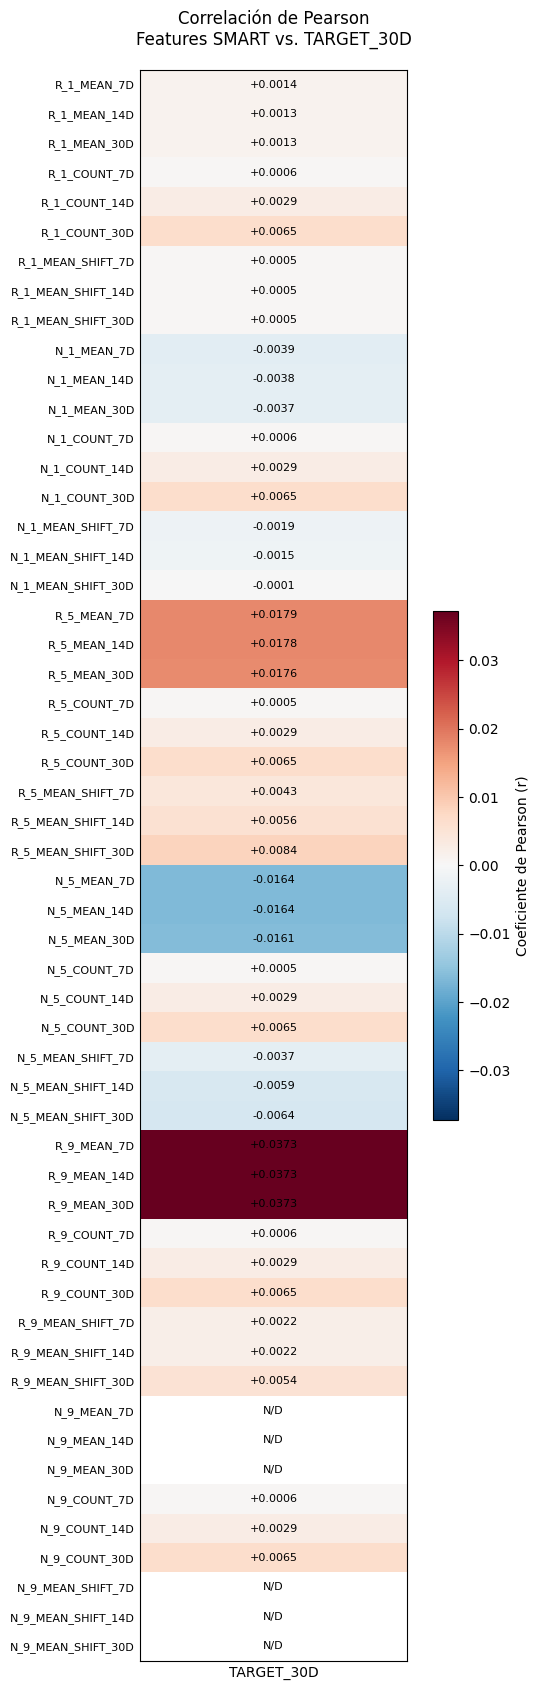

,TARGET_30D
R_1_MEAN_7D,0.001351
R_1_MEAN_14D,0.001328
R_1_MEAN_30D,0.001300
R_1_COUNT_7D,0.000550
R_1_COUNT_14D,0.002859
R_1_COUNT_30D,0.006538
R_1_MEAN_SHIFT_7D,0.000523
R_1_MEAN_SHIFT_14D,0.000473
R_1_MEAN_SHIFT_30D,0.000451
N_1_MEAN_7D,-0.003851


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Convertir los coeficientes a una sola columna.
valores = pd.to_numeric(correlaciones.iloc[0], errors="coerce")

matriz = pd.DataFrame({
    "TARGET_30D": valores
})

# Agrupar las features SMART por atributo, representación y ventana.
orden = [
    f"{campo}_{tipo}_{dias}D"
    for campo in ("R_1", "N_1", "R_5", "N_5", "R_9", "N_9")
    for tipo in ("MEAN", "COUNT", "MEAN_SHIFT")
    for dias in (7, 14, 30)
]

matriz = matriz.reindex(orden)

# Escala centrada en cero, adaptada a los valores observados.
limite = max(0.001, np.nanmax(np.abs(matriz.to_numpy(dtype=float))))
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)

fig, ax = plt.subplots(figsize=(5.5, 17))

imagen = ax.imshow(
    matriz.to_numpy(dtype=float),
    cmap="RdBu_r",
    norm=norma,
    aspect="auto"
)

ax.set_xticks([0], ["TARGET_30D"])
ax.set_yticks(range(len(matriz)), matriz.index, fontsize=8)

ax.set_title(
    "Correlación de Pearson\nFeatures SMART vs. TARGET_30D",
    fontsize=12,
    pad=18
)

# Mostrar el coeficiente dentro de cada celda.
for i, valor in enumerate(matriz["TARGET_30D"]):
    etiqueta = f"{valor:+.4f}" if pd.notna(valor) else "N/D"
    ax.text(
        0, i, etiqueta,
        ha="center",
        va="center",
        fontsize=8,
        color="black"
    )

fig.colorbar(
    imagen,
    ax=ax,
    label="Coeficiente de Pearson (r)",
    fraction=0.08,
    pad=0.08
)

ax.tick_params(axis="both", length=0)

plt.tight_layout()
plt.show()

matriz

La validacion presentada es interesante debido a que demuestra una de las posibilidades de los datos en terminos de
la informacion que anaden. Notese que en algunas de las SMART calculadas, es mucho mas importante  su MEAN que los
cambios de esta durante varios periodos de tiempo, en donde la correlacion disminuye a medida que se considerean
ventanas mas grandes. En el caso de R1_MEAN, notamos que la correlacion disminuye rapidamente hasta llegar a la
ventana final de 30 dias, mientras que el conteo demuestra un comportamiento menos estable, en donde el conteo de
la mediciones enla ventana de 30 dias tiene una correlacion mayor que las ventnas anteriores.

En algunas variables, ademas, los valores de la correlacion resultante entre estas y el target resultan similares,
para los contadores de R1, R5, R9 y N1 en el caso de los 7 dias la correlacion es similar. lo que demuestra que
internamente existen variables que se mueven de manera similar con el objetivo, teniendo relaciones numericas similares.

Un caso interesante es el de las metricas N9 mean shift que mantiene un valore de N/A o nulo en todas las ventanas.
La correlacion de pearson requiere de tener una variacion en los datos, por lo que esto demuestra que la variable no
tiene valores diferentes en los registros evaluados, resultando en una correlacion nula. Esto es un indicio de que la variable no aporta informacion al modelo, y puede ser descartada de manera segura.

In [49]:
n9_diagnostico = consultar(f"""
    SELECT
        COUNT(N_9_MEAN_7D) AS REGISTROS_VALIDOS,
        COUNT(DISTINCT N_9_MEAN_7D) AS VALORES_DISTINTOS,
        MIN(N_9_MEAN_7D) AS MINIMO,
        MAX(N_9_MEAN_7D) AS MAXIMO,
        STDDEV(N_9_MEAN_7D) AS DESVIACION
    FROM {obt}
    WHERE TARGET_30D IS NOT NULL
""", max_filas=1)

n9_diagnostico

,REGISTROS_VALIDOS,VALORES_DISTINTOS,MINIMO,MAXIMO,DESVIACION
0,110091736,1,100.0000000000,100.0000000000,0.0


In [8]:
evidencia = consultar(f"""
    SELECT LABEL_STATUS,
           COUNT(*) AS OBSERVACIONES,
           AVG(R_5_MEAN_SHIFT_7D) AS PROM_R5_SHIFT_7D,
           AVG(R_9_MEAN_30D) AS PROM_R9_MEAN_30D,
           COUNT(R_5_MEAN_SHIFT_7D) AS DATOS_R5_SHIFT,
           COUNT(R_9_MEAN_30D) AS DATOS_R9_MEAN
    FROM {obt}
    WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
    GROUP BY LABEL_STATUS
    ORDER BY LABEL_STATUS
""", max_filas=2)
display(evidencia)

,LABEL_STATUS,OBSERVACIONES,PROM_R5_SHIFT_7D,PROM_R9_MEAN_30D,DATOS_R5_SHIFT,DATOS_R9_MEAN
0,NEGATIVE,109800252,0.089708190914,9645.207780744012,107947445,109800232
1,POSITIVE,291528,0.939944055802,13534.741287228296,289387,291528
